In [15]:
import os, json, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

API = "https://api.github.com/repos/StackExchange/Survey/contents/packages/archive"
MEDIA = "https://media.githubusercontent.com/media/StackExchange/Survey/main/packages/archive"
'''
def is_pointer(path):
    if not os.path.exists(path) or os.path.getsize(path) > 1024:
        return False
    with open(path, "rb") as fh:
        return fh.read(40).startswith(b"version https://git-lfs")

for y in range(2011, 2027):
    folder = f"data/{y}"
    os.makedirs(folder, exist_ok=True)
    try:
        info = json.loads(urllib.request.urlopen(f"{API}/{y}").read())
    except Exception as e:
        print(f"Skipping {y}: {e}")
        continue
    for f in info:
        if not f["name"].endswith((".csv", ".pdf")):
            continue
        dest = f"{folder}/{f['name']}"
        if os.path.exists(dest) and not is_pointer(dest):
            continue  # already have the real file
        print(f"Downloading {y}/{f['name']}...")
        urllib.request.urlretrieve(f"{MEDIA}/{y}/{f['name']}", dest)'''
print("Done.")

Done.


In [16]:
df = pd.read_csv("data/2017/results.csv", low_memory=False)
df.shape

(51392, 154)

In [17]:
df.head()

,Respondent,Professional,ProgramHobby,Country,University,EmploymentStatus,FormalEducation,MajorUndergrad,HomeRemote,CompanySize,...,StackOverflowMakeMoney,Gender,HighestEducationParents,Race,SurveyLong,QuestionsInteresting,QuestionsConfusing,InterestedAnswers,Salary,ExpectedSalary
0,1,Student,"Yes, both",United States,No,"Not employed, and not looking for work",Secondary school,NaN,NaN,NaN,...,Strongly disagree,Male,High school,White or of European descent,Strongly disagree,Strongly agree,Disagree,Strongly agree,NaN,NaN
1,2,Student,"Yes, both",United Kingdom,"Yes, full-time",Employed part-time,Some college/university study without earning ...,Computer science or software engineering,"More than half, but not all, the time",20 to 99 employees,...,Strongly disagree,Male,A master's degree,White or of European descent,Somewhat agree,Somewhat agree,Disagree,Strongly agree,NaN,37500.0
2,3,Professional developer,"Yes, both",United Kingdom,No,Employed full-time,Bachelor's degree,Computer science or software engineering,"Less than half the time, but at least one day ...","10,000 or more employees",...,Disagree,Male,A professional degree,White or of European descent,Somewhat agree,Agree,Disagree,Agree,113750.0,NaN
3,4,Professional non-developer who sometimes write...,"Yes, both",United States,No,Employed full-time,Doctoral degree,A non-computer-focused engineering discipline,"Less than half the time, but at least one day ...","10,000 or more employees",...,Disagree,Male,A doctoral degree,White or of European descent,Agree,Agree,Somewhat agree,Strongly agree,NaN,NaN
4,5,Professional developer,"Yes, I program as a hobby",Switzerland,No,Employed full-time,Master's degree,Computer science or software engineering,Never,10 to 19 employees,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1. Checking if any rows are identical - Code

#### What it means: 
a duplicate is a row that’s an exact copy of another row. Usually it’s the same person submitted twice, or a glitch when files were merged. Copies count one person’s answers twice and skew your results.

also Respondent is just a row number, so you leave it out when comparing rows. Otherwise no two rows could ever match.


In [18]:
#if any rows identical
answer_cols = df.columns.drop("Respondent")
dupes = df[df.duplicated(subset=answer_cols, keep=False)]
print(len(dupes))

#how many questions did those people actually answer?
df["n_answered"] = df.drop(columns="Respondent").notna().sum(axis=1)
print(dupes.notna().sum(axis=1).values)

18
[ 9  9  9  9  9  9  9  9 10  9  9  9  9  9 10  9  9  9]


### 1. Checking if any rows are identical - Analysis

Identical answers: 18 rows (9 pairs). At first glance these look like duplicates.
But they aren’t real duplicates. Each of those people answered only about 9 of the 154 questions. They’re all students from the US, UK or India who quit the survey early. With only nine answers, which were common ones like “Student” and “United States”, different people end up looking identical by coincidence.

Decision: keep them. Deleting them would remove real people. This is a good example of the lecture’s point: the data looked broken, but checking where it came from showed it wasn’t.

Takeaway: these people answered about 8 out of 153 questions. Different people giving that few, common answers will look identical by chance, so you keep these rows. This is also why the n_answered column is useful:

### 2. Visualize Sparsity of Salary Data - Code

Left chart: of everyone who took the survey, how many reported a salary (blue) and how many left it blank (grey).
Right chart: the same split for each group. A bar that’s entirely grey (0% answered) means that group was never asked. A partly grey bar, like full-time employees at 34%, means people were asked but many skipped it.

Reusing it for other years: each year names its columns differently, so you pass in the names. 

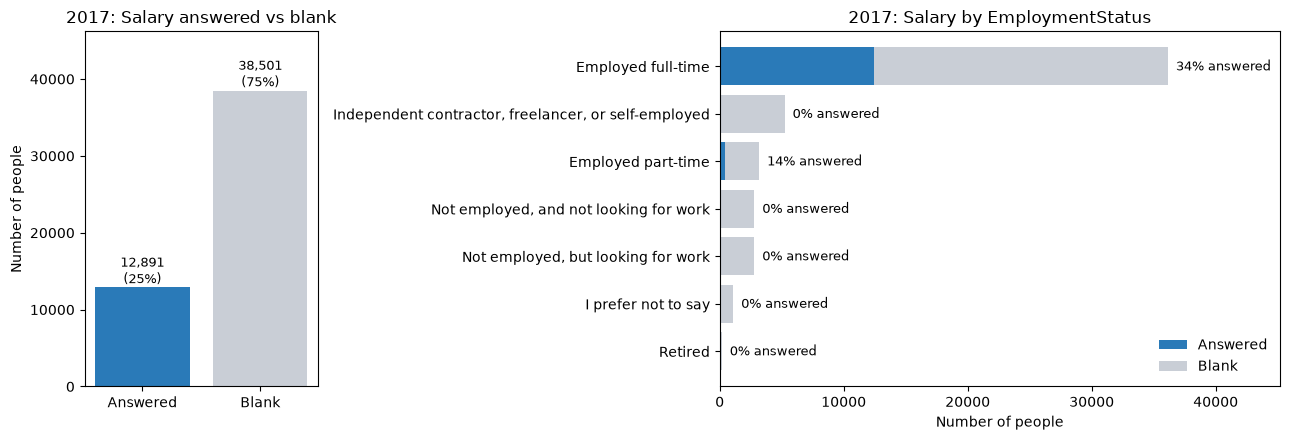

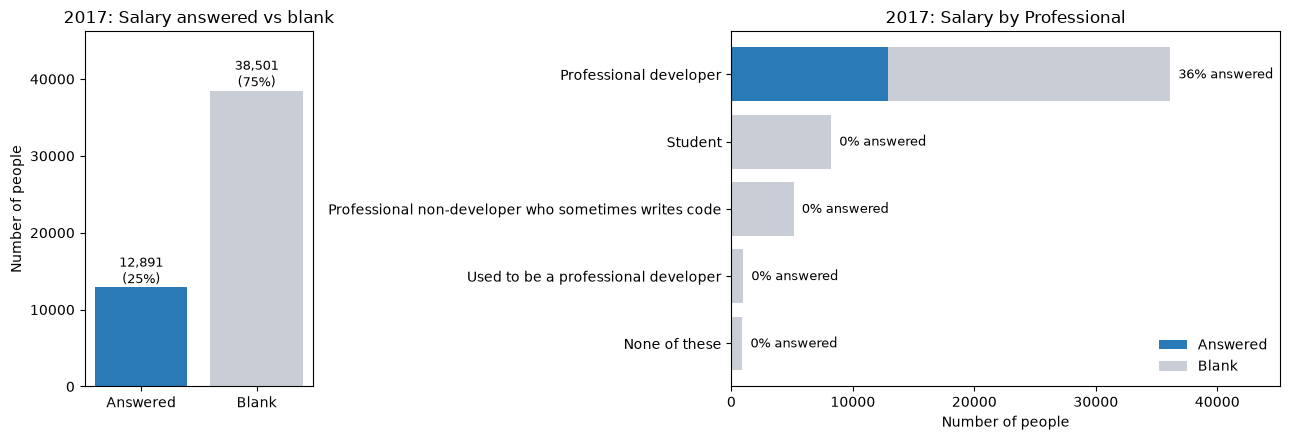

In [19]:

def plot_salary_sparsity(df, salary_col, group_col, year):
    """Show how many people answered the salary question, overall and by group."""
    answered = df[salary_col].notna()          # True = has a salary, False = blank

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5),
                                   gridspec_kw={"width_ratios": [1, 2.4]})

    # Left chart: answered vs blank, for everyone
    counts = answered.map({True: "Answered", False: "Blank"}).value_counts()
    counts = counts.reindex(["Answered", "Blank"], fill_value=0)
    bars = ax1.bar(counts.index, counts.values, color=["#2a7ab8", "#c9ced6"])
    for b, v in zip(bars, counts.values):
        ax1.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(df):.0%})",
                 ha="center", va="bottom", fontsize=9)
    ax1.set_title(f"{year}: {salary_col} answered vs blank")
    ax1.set_ylabel("Number of people")
    ax1.set_ylim(0, counts.max() * 1.2)

    # Right chart: the same split, for each group (e.g. employment status)
    groups = df[group_col].fillna("(blank)")
    tab = pd.crosstab(groups, answered).reindex(columns=[True, False], fill_value=0)
    tab = tab.loc[tab.sum(axis=1).sort_values().index]      # biggest group on top
    ax2.barh(tab.index, tab[True], color="#2a7ab8", label="Answered")
    ax2.barh(tab.index, tab[False], left=tab[True], color="#c9ced6", label="Blank")
    for i, (a, b) in enumerate(zip(tab[True], tab[False])):
        ax2.text(a + b, i, f"  {a/(a+b):.0%} answered", va="center", fontsize=9)
    ax2.set_title(f"{year}: {salary_col} by {group_col}")
    ax2.set_xlabel("Number of people")
    ax2.set_xlim(0, tab.sum(axis=1).max() * 1.25)
    ax2.legend(loc="lower right", frameon=False)

    plt.tight_layout()
    plt.show()

# 2017
df = pd.read_csv("data/2017/results.csv", low_memory=False)
plot_salary_sparsity(df, "Salary", "EmploymentStatus", 2017)
plot_salary_sparsity(df, "Salary", "Professional", 2017)

### 3. Visualize Sparsity of Overall Data - More code
This chart is a histogram: it groups people by how many questions they answered and draws a bar for each count. The bar’s height is how many people answered exactly that many questions. It works for any year.

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


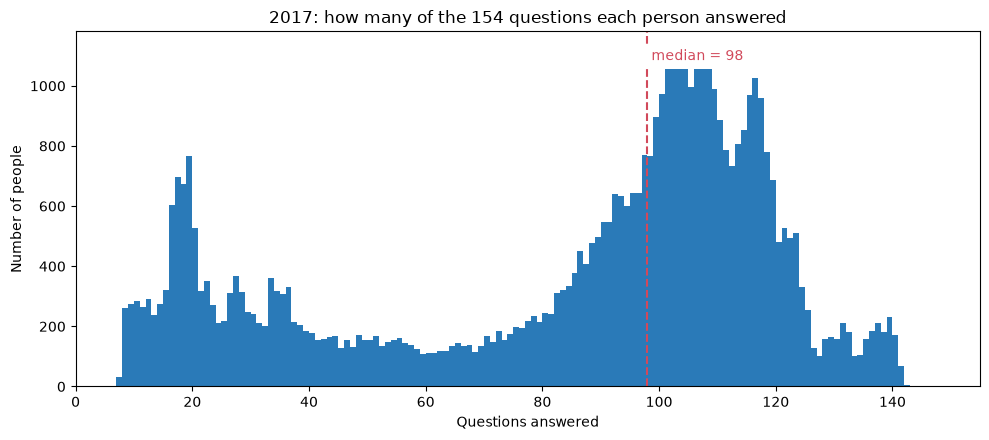

2017: 51,392 people | median 98 of 154 | under 20 answered: 4,976 (10%)


In [31]:

def plot_answer_spread(df, year, id_col="Respondent"):
    """Histogram of how many questions each person answered."""
    n = df.drop(columns=id_col).notna().sum(axis=1)   # answers per person (ID excluded)
    total = df.shape[1] - 1                            # number of questions

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.hist(n, bins=range(0, total + 2), color="#2a7ab8")   # one bar per count

    med = n.median()
    ax.axvline(med, color="#d1495b", linestyle="--", linewidth=1.5)
    ax.text(med, ax.get_ylim()[1] * 0.95, f" median = {med:.0f} ",
            color="#d1495b", va="top", bbox=dict(facecolor="white", edgecolor="none"))

    ax.set_title(f"{year}: how many of the {total} questions each person answered")
    ax.set_xlabel("Questions answered")
    ax.set_ylabel("Number of people")
    ax.set_xlim(0, total + 1)
    plt.tight_layout()
    plt.show()

    print(f"{year}: {len(n):,} people | median {med:.0f} of {total} | "
          f"under 20 answered: {(n < 20).sum():,} ({(n < 20).mean():.0%})")

plot_answer_spread(df, 2017)

### 3. Visualize Sparsity of Overall Data - Analysis

There are two humps. A distribution with two humps is called bimodal, and here it means there are two kinds of respondents:
Left hump (about 8–40 answers): people who quit early. The spike near 18–20 is probably where many of them stopped, for example a long or personal page. About 5,000 people (10%) answered fewer than 20.
Right hump (about 85–125 answers): people who finished most of the survey.
The median is 98. Half of respondents answered more than 98 questions and half answered fewer.
Nobody answered all 153, and the maximum is about 141. That’s expected: the survey only shows some questions to some people. Students get ExpectedSalary instead of Salary, for example, so nobody sees every question.
The little bump around 130–140 is probably people who saw extra question branches, such as the “ex-coder” questions.



### 4. Salary distribution, the main outlier check - code

Question: what does a typical salary look like, and what’s strange?
Charts:

A histogram of salary. It will probably be right-skewed: most people in the middle, with a long tail of high earners.
The same histogram on a log scale. A log scale squeezes big numbers together, which makes the low end ($0, under $1,000) easy to see.
A box plot (the Q1/Q3/IQR chart from Lecture 1), which marks outliers automatically using the 1.5 × IQR rule from HW1.

This is where you’ll look into the $0 salaries, the 318 under $1,000, and the suspicious $197,000 cap. (for 2017)

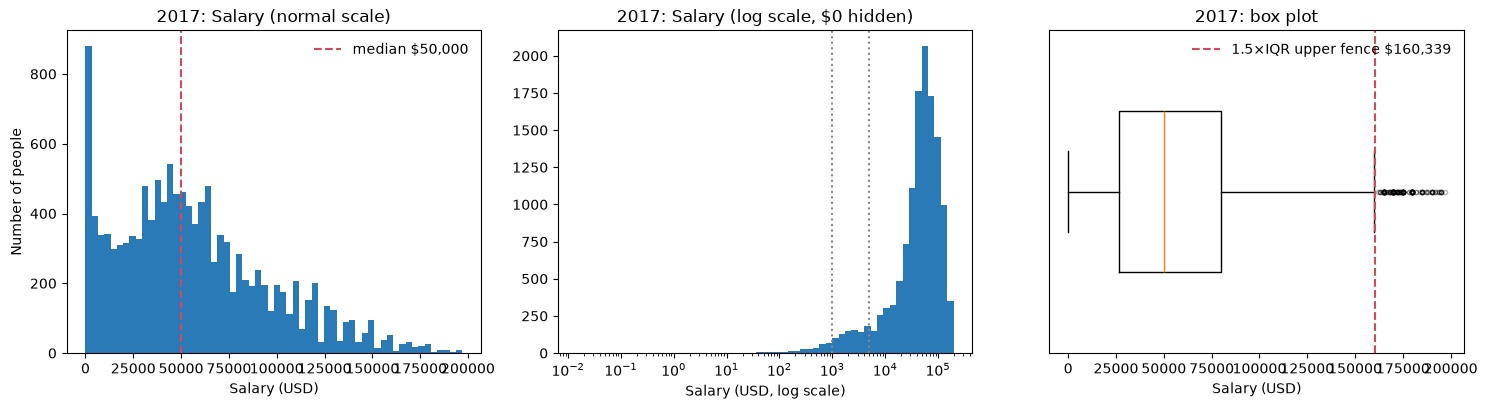

n=12,891  median=$50,000  min=$0.00  max=$197,000
IQR fences: low $-53,899, high $160,339
above high fence: 157
exactly $0: 6  |  under $1,000: 318  |  under $5,000: 1109


In [22]:
def plot_salary_distribution(df, salary_col, year):
    """Three views of salary: normal histogram, log histogram, box plot."""
    s = df[salary_col].dropna()                        # only people who answered
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr   # HW1's outlier rule

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.2))

    # 1. Normal histogram
    ax1.hist(s, bins=60, color="#2a7ab8")
    ax1.axvline(s.median(), color="#d1495b", ls="--", label=f"median ${s.median():,.0f}")
    ax1.set_title(f"{year}: {salary_col} (normal scale)")
    ax1.set_xlabel("Salary (USD)"); ax1.set_ylabel("Number of people")
    ax1.legend(frameon=False)

    # 2. Log-scale histogram (log can't show $0, so those are left out)
    pos = s[s > 0]
    ax2.hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60),
             color="#2a7ab8")
    ax2.set_xscale("log")
    for x in [1000, 5000]:
        ax2.axvline(x, color="#888", ls=":")           # reference lines at $1k and $5k
    ax2.set_title(f"{year}: {salary_col} (log scale, $0 hidden)")
    ax2.set_xlabel("Salary (USD, log scale)")

    # 3. Box plot
    ax3.boxplot(s, orientation="horizontal", widths=0.5, flierprops=dict(marker=".", alpha=0.3))
    ax3.axvline(high_fence, color="#d1495b", ls="--",
                label=f"1.5×IQR upper fence ${high_fence:,.0f}")
    ax3.set_title(f"{year}: box plot"); ax3.set_xlabel("Salary (USD)"); ax3.set_yticks([])
    ax3.legend(frameon=False, loc="upper right")

    plt.tight_layout()
    plt.show()

    print(f"n={len(s):,}  median=${s.median():,.0f}  min=${s.min():,.2f}  max=${s.max():,.0f}")
    print(f"IQR fences: low ${low_fence:,.0f}, high ${high_fence:,.0f}")
    print(f"above high fence: {(s > high_fence).sum():,}")
    print(f"exactly $0: {(s == 0).sum()}  |  under $1,000: {(s < 1000).sum()}  |  under $5,000: {(s < 5000).sum()}")

plot_salary_distribution(df, "Salary", 2017)

### 4. Salary distribution, the main outlier check - Analysis

What the charts show

1. Normal scale: most salaries fall between 25k and 100k, with a long tail to the right. That’s the right-skew we expected. There’s also a tall spike at the far left, near $0. That’s the first warning sign.

2. Log scale: this is the chart that shows the problem. Most salaries form one big hump around 10k–150k. To the left of the 1,000 line, there’s a thin trail of values stretching down to a few cents. Nobody earns $0.03 a year.

3. Box plot: the 1.5 × IQR rule flags 157 people above 160k as outliers. It flags nobody at the low end, because the lower fence is −$53,899 and salaries can’t be negative.

This is a useful lesson: the IQR rule from HW1 completely misses the real problem here. It flags plausible high US salaries and misses the impossible low ones. The rule assumes roughly symmetric data, and salary is heavily skewed.

What I found when I looked at the suspicious values

The low end (318 people under $1,000):

Salaries are already converted to US dollars. Currency records what people answered in, and Salary holds the converted USD amount. That’s why there are decimals, like $26,440.37.

Potentially these could be people typing in the wrong units. Some examples:
A US respondent reporting 150: maybe meant 150k, or entered a monthly or hourly figure.

All 318 are employed, so these aren’t unemployed people correctly reporting $0. They could be entry mistakes.
The most common countries are India (77), Poland, Russia and the US.

The high end:

The maximum is 197,000, and only 18 people are above $190k. Real developer surveys always have some people earning 300k+. It looks like Stack Overflow already removed or capped the highest values before publishing. Their documentation from that year may confirm this; ask your professor or check it.
So the 157 values above the IQR fence are probably real high earners, mostly in the US. Don’t remove them.

### 5. Salary by country - code
Question: is an “outlier” actually just a different country?
Chart: box plots of salary for the top 10–15 countries, side by side.
Why: $15k looks like an outlier in the US but is normal in India. Outlier checks should be done within groups, not across everyone at once.

The Salary column is already converted to USD, but you can work backwards to the original amount. The survey used one fixed exchange rate per currency, and you can find it from the most common values. For example, the most common euro salary is $32,258.06, which is exactly €30,000 ÷ 0.93. So the euro rate was 0.93. I found the rates for the biggest currencies the same way.

In [23]:
# 2017 exchange rates (local currency per 1 USD), found from the data itself
RATES_2017 = {"U.S. dollars ($)": 1, "Euros (€)": 0.93, "British pounds sterling (£)": 0.80,
    "Indian rupees (?)": 68.11, "Canadian dollars (C$)": 1.32, "Australian dollars (A$)": 1.32,
    "Polish zloty (zl)": 4.05, "Russian rubles (?)": 59.85, "Brazilian reais (R$)": 3.14,
    "Swedish kroner (SEK)": 8.84, "South African rands (R)": 13.47, "Swiss francs": 1.0}

# Everyone who gave a salary, plus their country's median and how many people that's based on
paid = df[df["Salary"].notna()].copy()
stats = paid.groupby("Country")["Salary"].agg(country_median="median", country_n="size")
paid = paid.join(stats, on="Country")

def guess(r):
    """Best guess at why a salary is so low."""
    if r.Salary == 0:
        return "zero"
    if r.country_n < 20:
        return "too few in country to judge"
    if 0.3 <= r.Salary * 12 / r.country_median <= 3:
        return "looks monthly"            # ×12 lands near the country's normal
    if r.Currency == "Indian rupees (?)" and 0.3 <= r.Salary * 100000 / r.country_median <= 3:
        return "looks like lakhs"         # e.g. typed 3 meaning ₹3,00,000
    if 0.3 <= r.Salary * 1000 / r.country_median <= 3:
        return "looks like thousands"     # e.g. typed 80 meaning 80k
    return "unclear"

low = paid[paid["Salary"] < 1000].copy()
low["local_amount"] = (low["Salary"] * low["Currency"].map(RATES_2017)).round(2)
low["guess"] = low.apply(guess, axis=1)

print(low["guess"].value_counts())
cols = ["Respondent", "Country", "Currency", "Salary", "local_amount", "country_median", "guess"]
low[cols].sort_values("Salary")

guess
looks monthly                  176
unclear                         48
looks like thousands            44
too few in country to judge     33
looks like lakhs                11
zero                             6
Name: count, dtype: int64


,Respondent,Country,Currency,Salary,local_amount,country_median,guess
23953,23954,Colombia,NaN,0.000000,NaN,11000.000000,zero
23907,23908,Sweden,Swedish kroner (SEK),0.000000,0.0,49547.511312,zero
51144,51145,Australia,Australian dollars (A$),0.000000,0.0,66856.060606,zero
4517,4518,India,Canadian dollars (C$),0.000000,0.0,7047.423286,zero
44841,44842,Japan,Japanese yen (¥),0.000000,NaN,31355.858595,zero
...,...,...,...,...,...,...,...
10057,10058,Poland,Polish zloty (zl),987.654321,4000.0,19753.086420,looks monthly
28958,28959,Poland,Polish zloty (zl),987.654321,4000.0,19753.086420,looks monthly
15857,15858,Poland,Polish zloty (zl),987.654321,4000.0,19753.086420,looks monthly
45702,45703,Poland,Polish zloty (zl),987.654321,4000.0,19753.086420,looks monthly


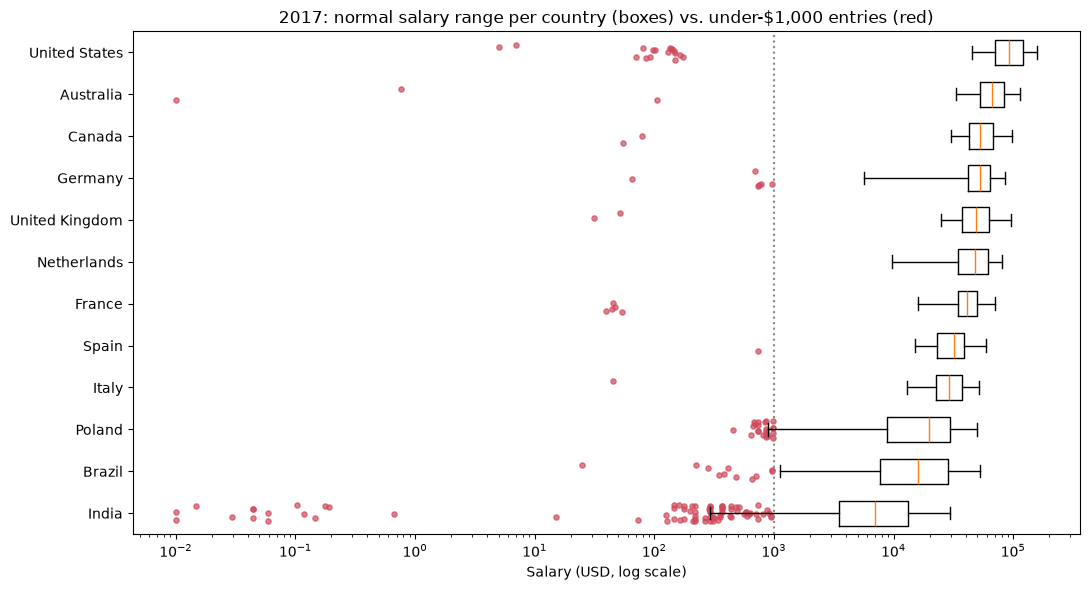

In [24]:
top = paid["Country"].value_counts().head(12).index
sub = paid[paid["Country"].isin(top)]
order = sub.groupby("Country")["Salary"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot([sub.loc[sub.Country == c, "Salary"].clip(lower=1) for c in order],
           orientation="horizontal", tick_labels=order,
           showfliers=False, widths=0.6, whis=(5, 95))
for i, c in enumerate(order, start=1):
    pts = sub.loc[(sub.Country == c) & (sub.Salary < 1000), "Salary"].clip(lower=0.01)
    ax.scatter(pts, np.full(len(pts), i) + np.random.uniform(-0.2, 0.2, len(pts)),
               color="#d1495b", s=14, alpha=0.7)
ax.set_xscale("log")
ax.axvline(1000, color="#888", ls=":")
ax.set_xlabel("Salary (USD, log scale)")
ax.set_title("2017: normal salary range per country (boxes) vs. under-$1,000 entries (red)")
plt.tight_layout()
plt.show()

### 5. Salary by country - Analysis
Each box spans the middle 50% of salaries in that country.
The whiskers (the lines sticking out of each box) cover from the 5th to the 95th percentile. That’s the “normal range”.
Each red dot is one under-1,000 salary. I spread the dots up and down a little at random so they don’t sit on top of each other. This is called jitter.
.clip(lower=0.01) nudges $0 values up to one cent, because a log scale can’t show zero.
What the chart and table actually show

Confirmed: almost all the red dots sit far to the left of their country’s box, often 100× or more below normal. So relative to their own country, they really are abnormal.

Corrected: the biggest cause is monthly salaries, not “thousands”.

#### Guess, Count, Typical example

Looks monthly - 176	- Indian respondent typed ₹20,000 (a normal monthly pay), and Poland 3,500 zł. Both are about right per month, so this is the most common mistake

Looks like thousands - 44 - US respondents typing 80, 102, 140: almost certainly 80k, 102k, 140k. France €42 is probably €42k

Looks like lakhs - 11 - Indian respondents typing ₹2, ₹3, ₹4. Indians often count in lakhs (1 lakh = ₹100,000), so ₹3 likely means ₹3,00,000

Zero - 6 - $0, so no way to tell what they meant

Too few in country to judge	 - 33 - e.g. Cuba, Zimbabwe, Sri Lanka. With so few people, the country’s median isn’t reliable

Unclear - 48 - Doesn’t fit any pattern

Also corrected: not every low value is an error. The “too few to judge” group includes countries like Venezuela (400) and Cuba (560), where pay really was very low in 2017. “All 318 are employed” is true, but that only rules out unemployed people reporting $0. It doesn’t make every low number a mistake.

Another finding from the chart: India’s and Poland’s whiskers reach down toward 300–1,000. The monthly entries are so common in those countries that they drag the low end of the box down. So some monthly entries probably sit above 1,000 too. That’s the 1,000–5,000 grey zone from before.

### 6. Salary against likely features - code

Question: which columns seem related to salary? These are the features (model inputs) that might help predict it.

Before plotting, this makes a temporary cleaned salary column so the bad low values don’t skew the boxes. This keeps the original Salary untouched, so your group can still choose a different fix later:


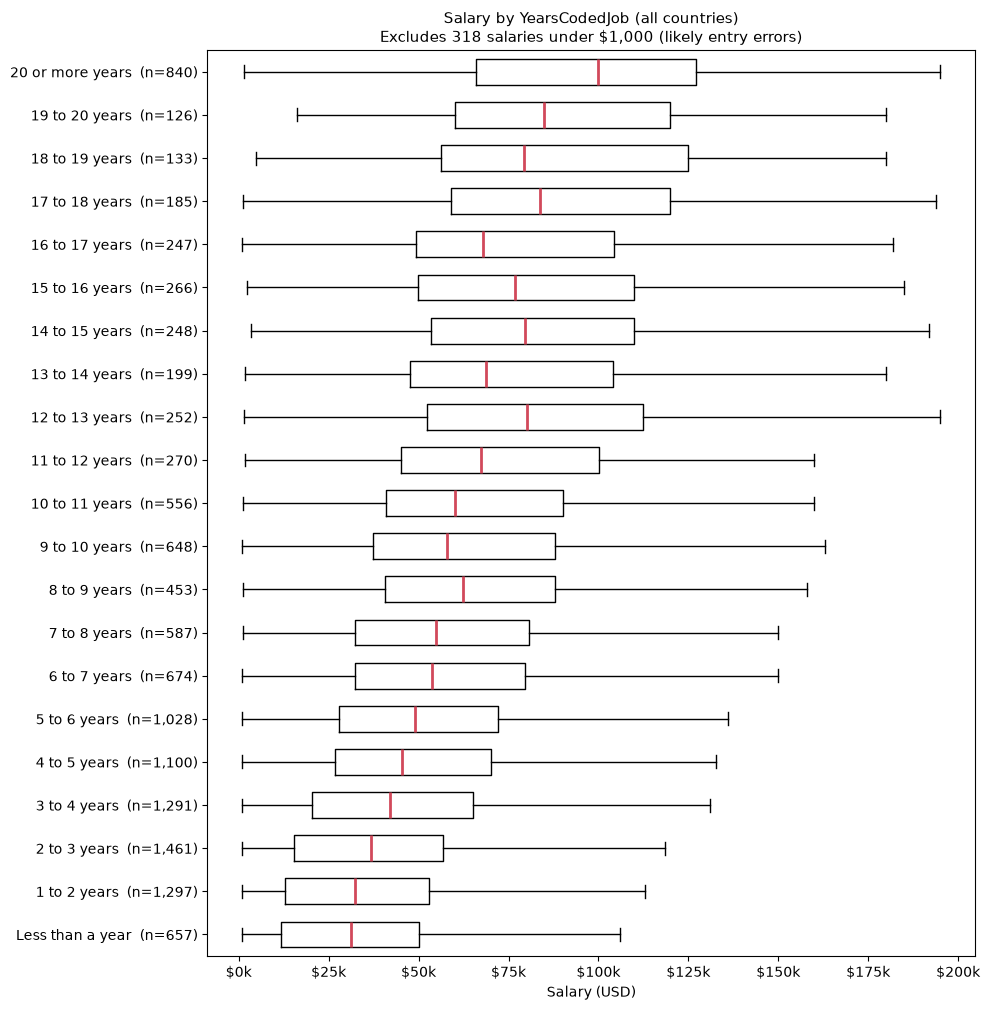

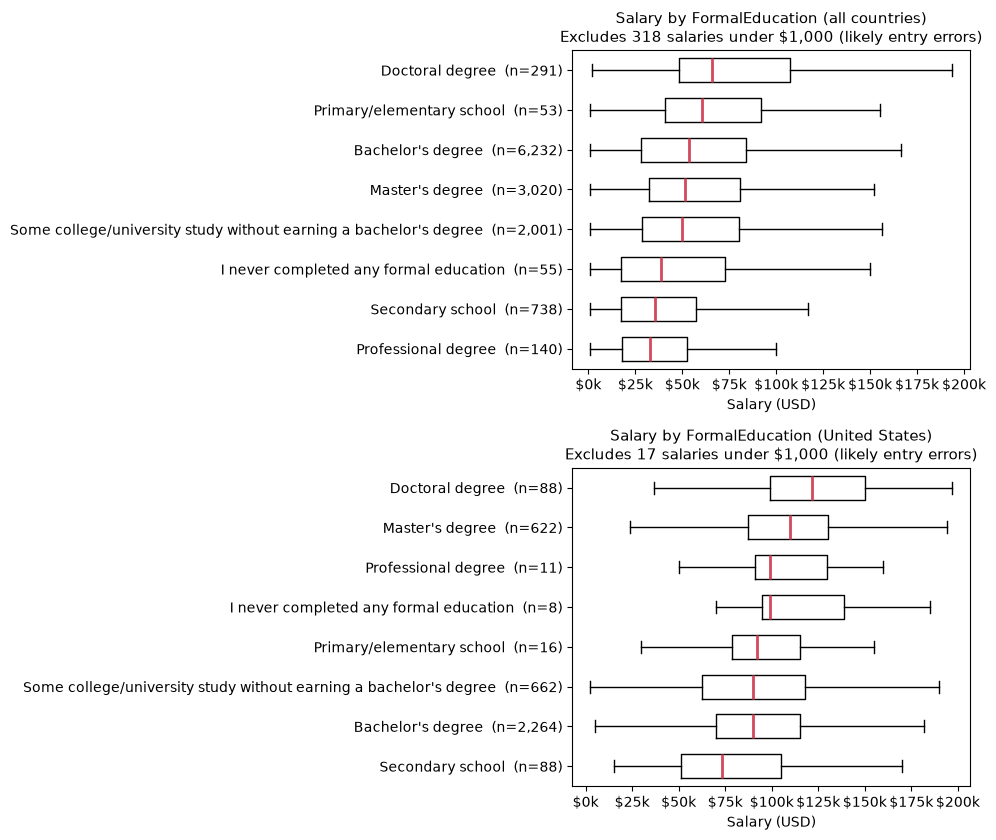

In [26]:
df["salary_clean"] = df["Salary"].where(df["Salary"] >= 1000)   # under $1,000 → blank

NON_ANSWERS = ["I prefer not to answer", "I prefer not to say", "I don't know"]

def plot_salary_by(df, feature, salary_col="salary_clean", raw_col="Salary",
                   order=None, country=None, ax=None):
    """Box plot of salary for each answer to one question, noting excluded values."""
    base = df if country is None else df[df["Country"] == country]
    data = base[base[salary_col].notna() & base[feature].notna()]
    data = data[~data[feature].isin(NON_ANSWERS)]

    if order is None:
        order = data.groupby(feature)[salary_col].median().sort_values().index
    order = [o for o in order if o in set(data[feature])]

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.8))
    groups = [data.loc[data[feature] == o, salary_col] for o in order]
    ax.boxplot(groups, orientation="horizontal", showfliers=False, widths=0.6,
               medianprops=dict(color="#d1495b", linewidth=2))
    ax.set_yticks(range(1, len(order) + 1),
                  [f"{o}  (n={len(g):,})" for o, g in zip(order, groups)])

    # Title, plus a note on how many salaries were excluded
    title = f"Salary by {feature} ({country or 'all countries'})"
    if raw_col in base and salary_col != raw_col:
        dropped = (base[raw_col].notna() & base[salary_col].isna()).sum()
        title += f"\nExcludes {dropped:,} salaries under $1,000 (likely entry errors)"
    ax.set_title(title, fontsize=11)

    ax.set_xlabel("Salary (USD)")
    ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}k")
    return ax

YEARS_ORDER = ["Less than a year", "1 to 2 years", "2 to 3 years", "3 to 4 years",
    "4 to 5 years", "5 to 6 years", "6 to 7 years", "7 to 8 years", "8 to 9 years",
    "9 to 10 years", "10 to 11 years", "11 to 12 years", "12 to 13 years",
    "13 to 14 years", "14 to 15 years", "15 to 16 years", "16 to 17 years",
    "17 to 18 years", "18 to 19 years", "19 to 20 years", "20 or more years"]

plot_salary_by(df, "YearsCodedJob", order=YEARS_ORDER); plt.tight_layout(); plt.show()

fig, (a, b) = plt.subplots(2, 1, figsize=(10, 8.5))
plot_salary_by(df, "FormalEducation", ax=a)
plot_salary_by(df, "FormalEducation", country="United States", ax=b)
plt.tight_layout(); plt.show()

### 6. Salary against likely features - analysis

The (n=…) next to each label is how many people are in that group. A box built from 8 people can’t be trusted.

Four cleaning lessons from these charts

1. Ordered categories are stored as text and sort wrong.
YearsCodedJob holds answers like “2 to 3 years”. Pandas sorts text alphabetically, so “10 to 11 years” comes before “2 to 3 years”. Categories with a natural order are called ordinal. You have to give the order yourself, which is what YEARS_ORDER does. Before modeling, you’ll also convert them to numbers, e.g. “2 to 3 years” → 2.5 and “20 or more years” → 20 (note that choice in your write-up).

2. Some answers are hidden missing values.
“I prefer not to answer” and “I don’t know” aren’t blank, so .isna() doesn’t catch them. But they mean the same thing as no answer. The function skips them, and when you clean, convert them to NaN.

3. Experience is clearly related to salary.
In the years-coded chart, the median climbs steadily from about 31k (under a year) to $100k (20+ years). That makes it a strong feature. There are two similar columns:

YearsProgram: total years coding, including as a hobby.
YearsCodedJob: years coding professionally. This one is more closely tied to salary.

They overlap a lot, so when modeling you’d probably keep just one. Two columns that carry nearly the same information is called multicollinearity.

4. Overall results can mislead: the education example.

All countries (top chart): a master’s degree seems to earn less than a bachelor’s.
US only (bottom chart): a master’s earns more (110k vs $90k). I also checked Germany and India, and it’s the same there.

Why the flip? US respondents earn far more than everyone else and make up 36% of the bachelor’s group but only 21% of the master’s group. So the bachelor’s group’s overall average is pulled up by country, not by the degree. When a hidden third variable (here, country) distorts the relationship between two others, that’s called confounding. The extreme case, where the direction actually reverses, is called Simpson’s paradox.

Takeaway: always check salary relationships within a country (or include country as a feature). Otherwise your model may learn “where you live” and present it as “what degree you have”.

Also, odd results like “primary school earns more than a bachelor’s” in the top chart come from tiny groups (n=53). Don’t read anything into groups that small.

### 7. Value counts and imbalance - code

Question: does each category have enough people for a model to learn from?

Imbalance means some categories have far more people than others. A model learns mostly from the big groups. For a category with 12 people it barely learns anything, and any result for that group is unreliable.

Country: 133 categories | 97 have fewer than 50 | blank: 0%
Gender: 5 categories | 0 have fewer than 50 | blank: 32%


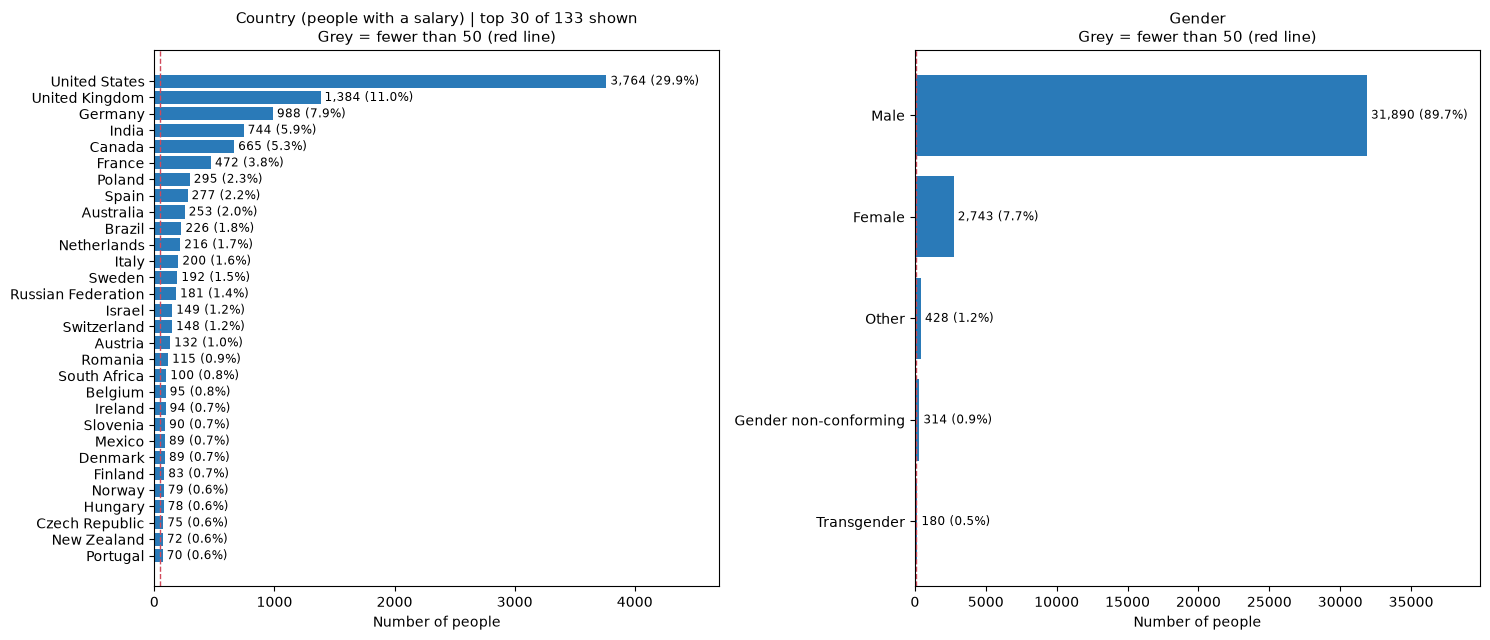

In [27]:
def plot_counts(df, col, top=20, multi=False, min_n=50, title_note="", ax=None):
    """Bar chart of how many people gave each answer; small groups shown in grey."""
    s = df[col].dropna()
    if multi:                                   # "Male; Other" → two separate answers
        s = s.str.split(";").explode().str.strip()
    counts = s.value_counts()
    shown = counts.head(top).sort_values()

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 0.32 * len(shown) + 1.6))
    colors = ["#c9ced6" if v < min_n else "#2a7ab8" for v in shown.values]
    ax.barh(shown.index, shown.values, color=colors)
    for i, v in enumerate(shown.values):
        ax.text(v, i, f" {v:,} ({v/counts.sum():.1%})", va="center", fontsize=8.5)
    ax.axvline(min_n, color="#d1495b", ls="--", lw=1)
    ax.set_xlim(0, shown.max() * 1.25)
    extra = f" | top {top} of {len(counts)} shown" if len(counts) > top else ""
    ax.set_title(f"{col}{title_note}{extra}\nGrey = fewer than {min_n} (red line)", fontsize=11)
    ax.set_xlabel("Number of people")

    small = (counts < min_n).sum()
    print(f"{col}: {len(counts)} categories | {small} have fewer than {min_n} | "
          f"blank: {df[col].isna().mean():.0%}")
    return ax

paid = df[df["salary_clean"].notna()]          # people with a usable salary

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 6.5))
plot_counts(paid, "Country", top=30, title_note=" (people with a salary)", ax=a)
plot_counts(df, "Gender", multi=True, ax=b)
plt.tight_layout(); plt.show()

# Also try: plot_counts(df, "FormalEducation"), plot_counts(paid, "CompanySize"),
#           plot_counts(df, "HaveWorkedLanguage", multi=True)

### 7. Value counts and imbalance - analysis

min_n=50 is the cutoff for “too small”. 50 is a common rule of thumb, not an official number, so you can change it.
multi=True is for questions where people could tick several answers. It splits on ; so each answer gets counted separately.
.explode() turns a row holding a list like ["Male", "Other"] into two rows, one per answer.
What it shows

Country is very lopsided.

Among people with a usable salary, the US alone is 30%. The top 5 countries (US, UK, Germany, India, Canada) are about 60%.
97 of 133 countries have fewer than 50 salary respondents, and 81 have fewer than 20. They’re not in the chart because it only shows the top 30, but the printed line reports them.
Why it matters: in Step 4, country turned out to be the biggest factor in salary. Yet for most countries there’s too little data to learn their salary level. Common fixes:
Group small countries into an “Other” category or by region (e.g. “Western Europe”, “South Asia”).
Limit the project to the countries with enough data, and say so in the write-up.
Use a country-level number instead, like average income per country, so small countries still get a sensible value.

Gender is very imbalanced, and has extra cleaning issues.

About 90% male, about 8% female, and 32% left it blank.
It’s a multi-select question: 418 people ticked more than one option, e.g. “Male; Other”. Counting raw values without splitting would treat “Male; Other” as its own category.
Percentages here are out of answers ticked, not people, because some people ticked two.
Why it matters: if gender becomes a feature, a model has few examples for the non-male groups, so results for them are less reliable. Also, gender questions in the survey changed across years, which matters later when you combine years.

Hidden “no answer” values show up here too. For example, Country has 140 people who chose “I prefer not to say”, which is really missing data, like the ones from Step 4.

### 8. Multi-select questions - code

The problem: HaveWorkedLanguage stores answers like "JavaScript; Python; Ruby; SQL" in a single text cell. A model can’t use that directly. It needs numbers.

The fix is one-hot encoding: make one column per option, holding 1 if the person ticked it and 0 if not.

Pandas does this in one line with .str.get_dummies(sep=";"). “Dummies” is another name for these 0/1 columns.

The function returns the 0/1 table (langs) without adding it to df, so your data stays unchanged.

Why only people who answered? Someone who left the question blank didn’t say they use no languages; we just don’t know. Giving them all 0s would wrongly claim they use nothing. So blanks stay out of the 0/1 table.

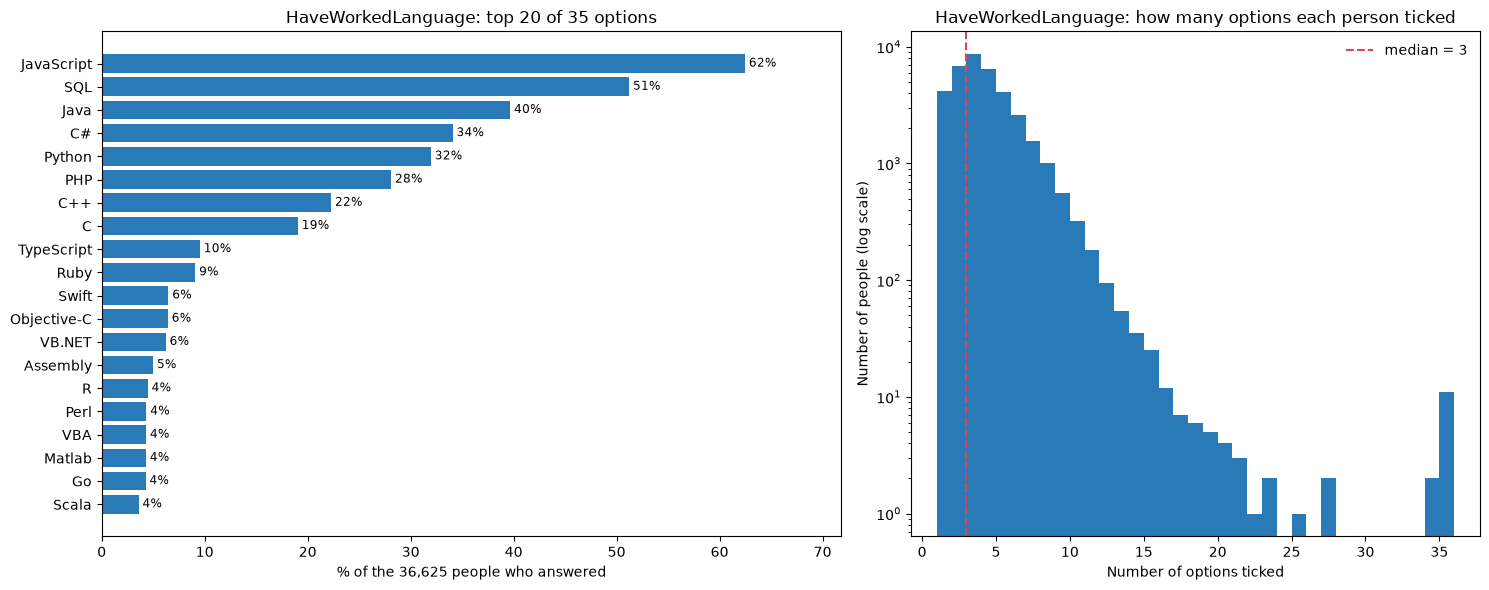

HaveWorkedLanguage: 71% answered | 35 options | median ticked 3 | ticked ALL 35: 11


,Assembly,C,C#,C++,Clojure,CoffeeScript,Common Lisp,Dart,Elixir,Erlang,...,Ruby,Rust,SQL,Scala,Smalltalk,Swift,TypeScript,VB.NET,VBA,Visual Basic 6
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [28]:
def explore_multiselect(df, col, top=20, sep=";"):
    """One-hot encode a multi-select question and chart it."""
    answered = df[col].notna()
    dummies = df.loc[answered, col].str.get_dummies(sep=sep)    # one 0/1 column per option
    dummies.columns = dummies.columns.str.strip()               # remove stray spaces from names
    dummies = dummies.T.groupby(level=0).max().T                # merge any names that matched after stripping
    n_picked = dummies.sum(axis=1)                              # options ticked per person
    share = dummies.mean().sort_values(ascending=False)         # % of people who ticked each

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})

    # Left: most common options
    shown = share.head(top).sort_values()
    ax1.barh(shown.index, shown.values * 100, color="#2a7ab8")
    for i, v in enumerate(shown.values):
        ax1.text(v * 100, i, f" {v:.0%}", va="center", fontsize=8.5)
    ax1.set_xlabel(f"% of the {answered.sum():,} people who answered")
    ax1.set_title(f"{col}: top {min(top, len(share))} of {len(share)} options")
    ax1.set_xlim(0, shown.max() * 100 * 1.15)

    # Right: how many options each person ticked
    ax2.hist(n_picked, bins=range(1, dummies.shape[1] + 2), color="#2a7ab8")
    ax2.axvline(n_picked.median(), color="#d1495b", ls="--", label=f"median = {n_picked.median():.0f}")
    ax2.set_yscale("log")
    ax2.set_xlabel("Number of options ticked"); ax2.set_ylabel("Number of people (log scale)")
    ax2.set_title(f"{col}: how many options each person ticked")
    ax2.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"{col}: {answered.mean():.0%} answered | {dummies.shape[1]} options | "
          f"median ticked {n_picked.median():.0f} | ticked ALL {dummies.shape[1]}: "
          f"{(n_picked == dummies.shape[1]).sum()}")
    return dummies

langs = explore_multiselect(df, "HaveWorkedLanguage")
langs.head()

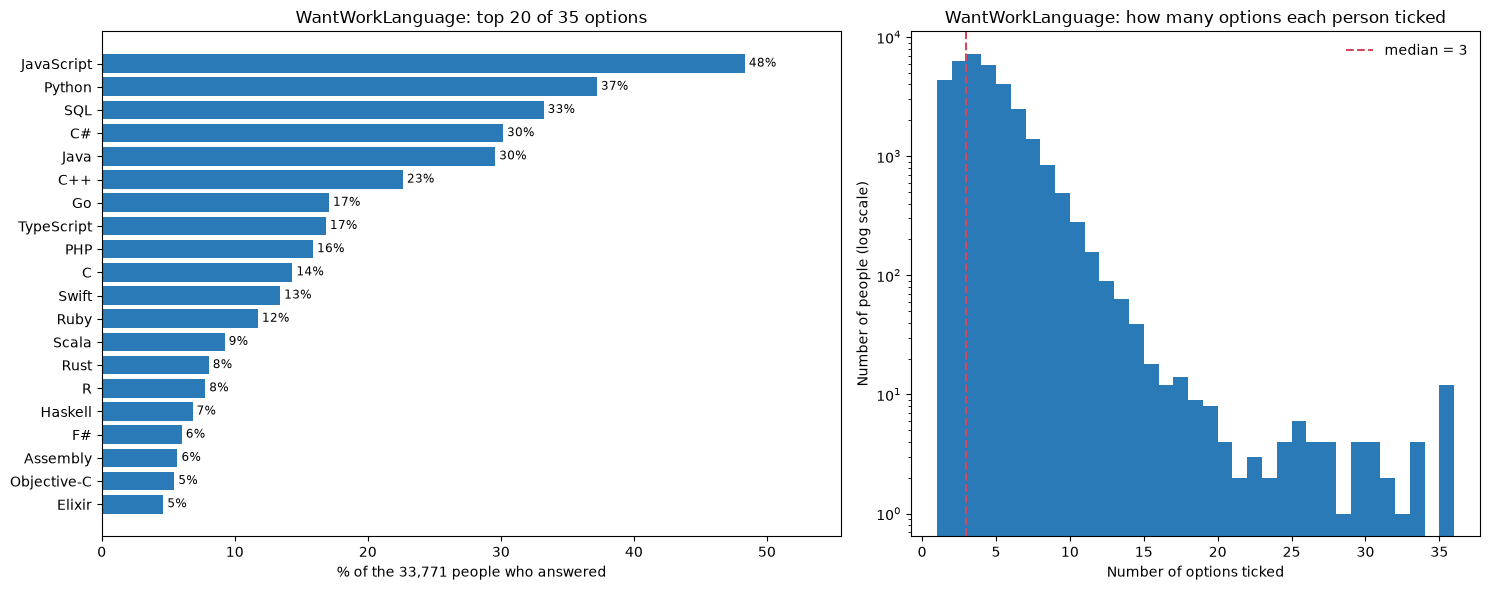

WantWorkLanguage: 66% answered | 35 options | median ticked 3 | ticked ALL 35: 12


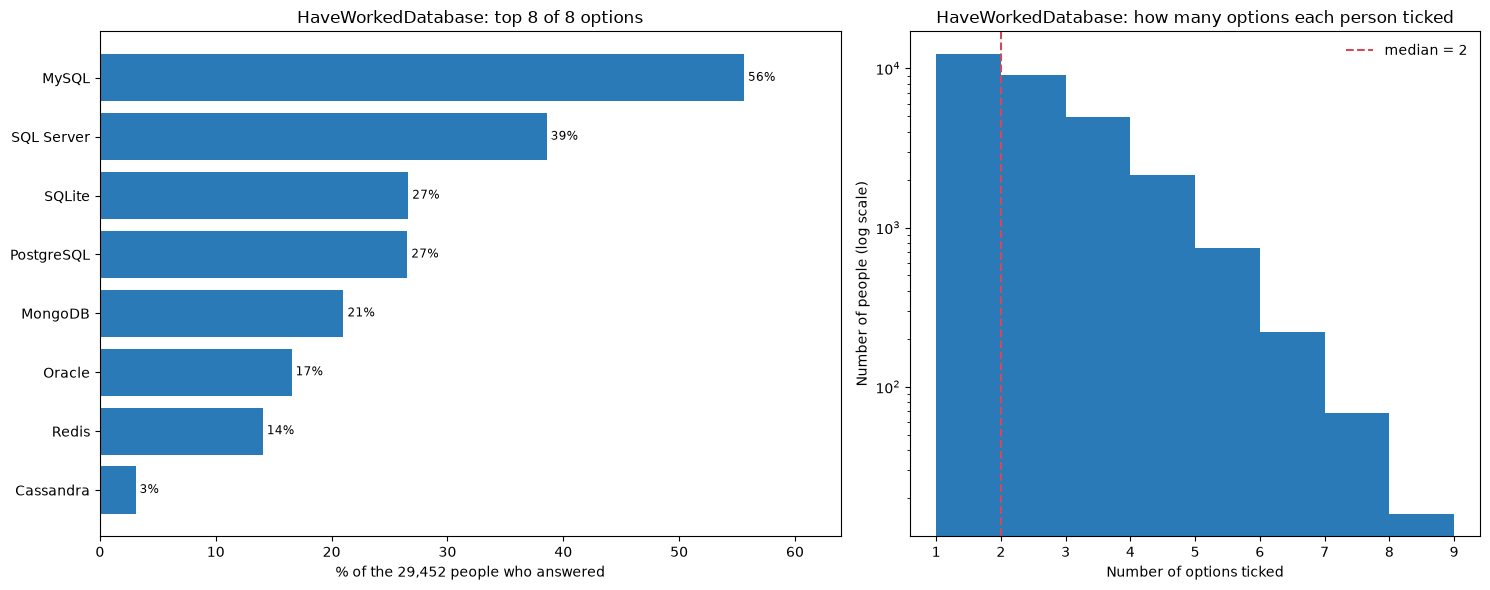

HaveWorkedDatabase: 57% answered | 8 options | median ticked 2 | ticked ALL 8: 16


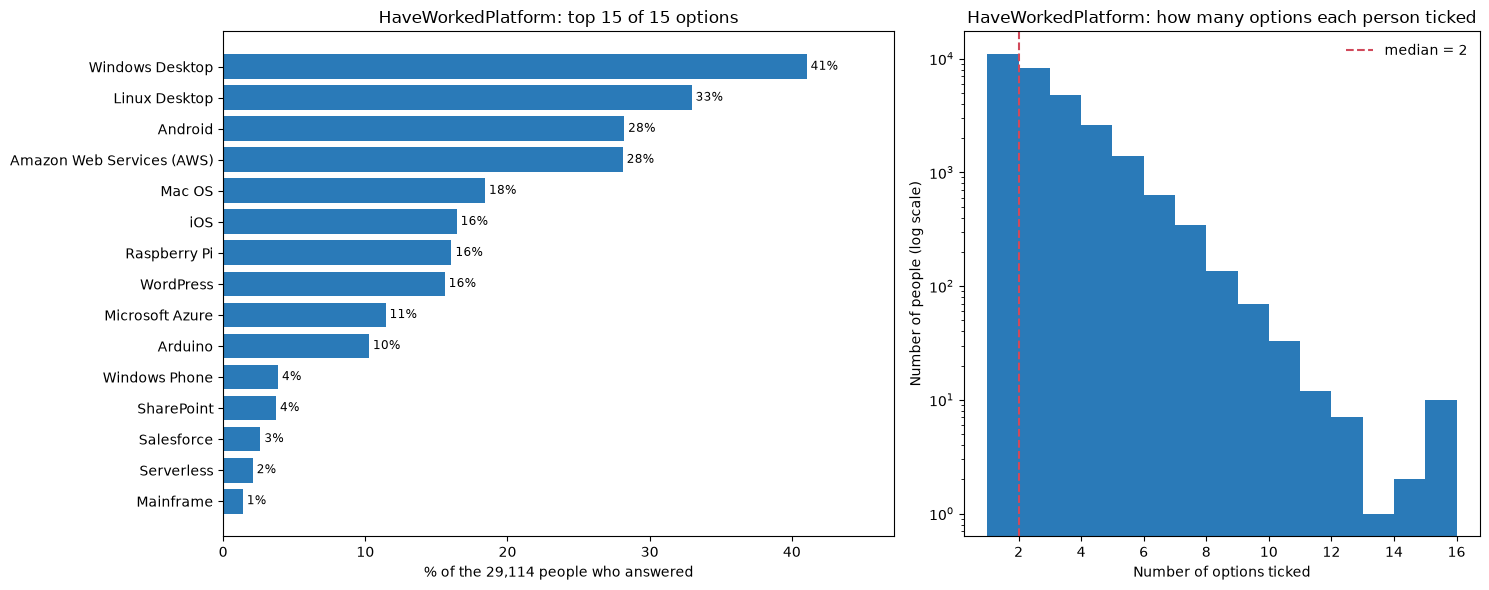

HaveWorkedPlatform: 57% answered | 15 options | median ticked 2 | ticked ALL 15: 10


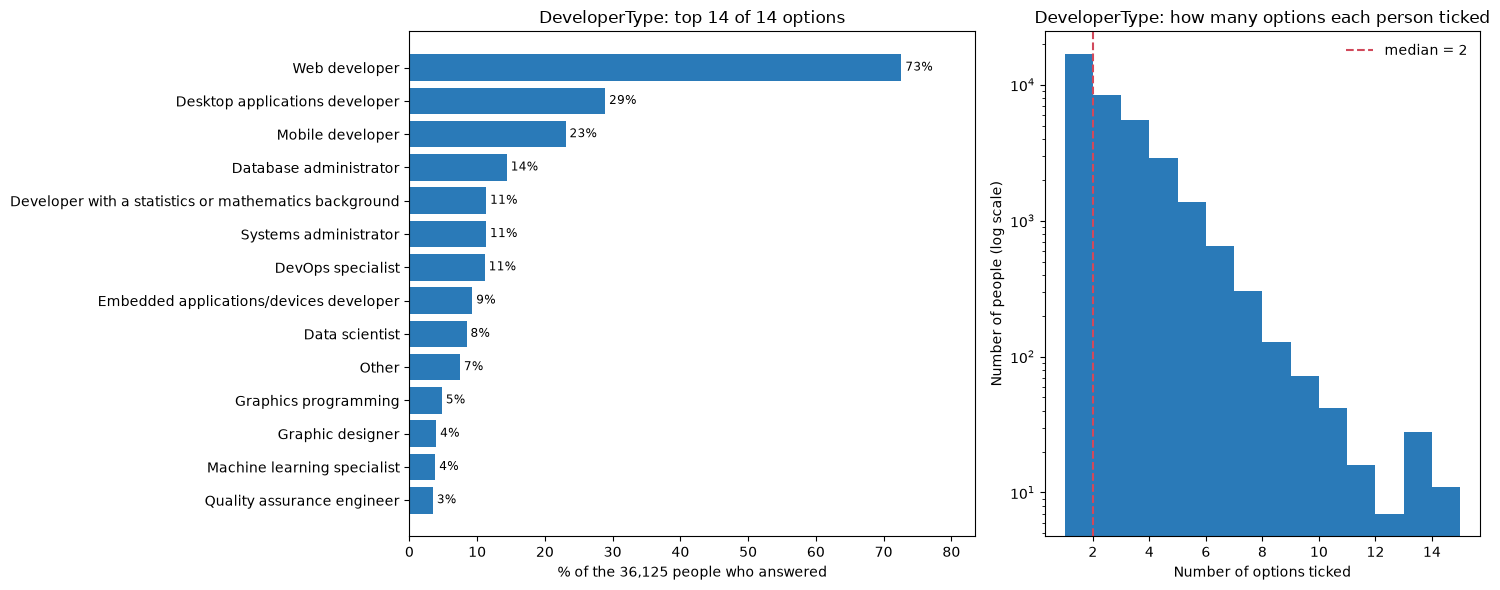

DeveloperType: 70% answered | 14 options | median ticked 2 | ticked ALL 14: 11


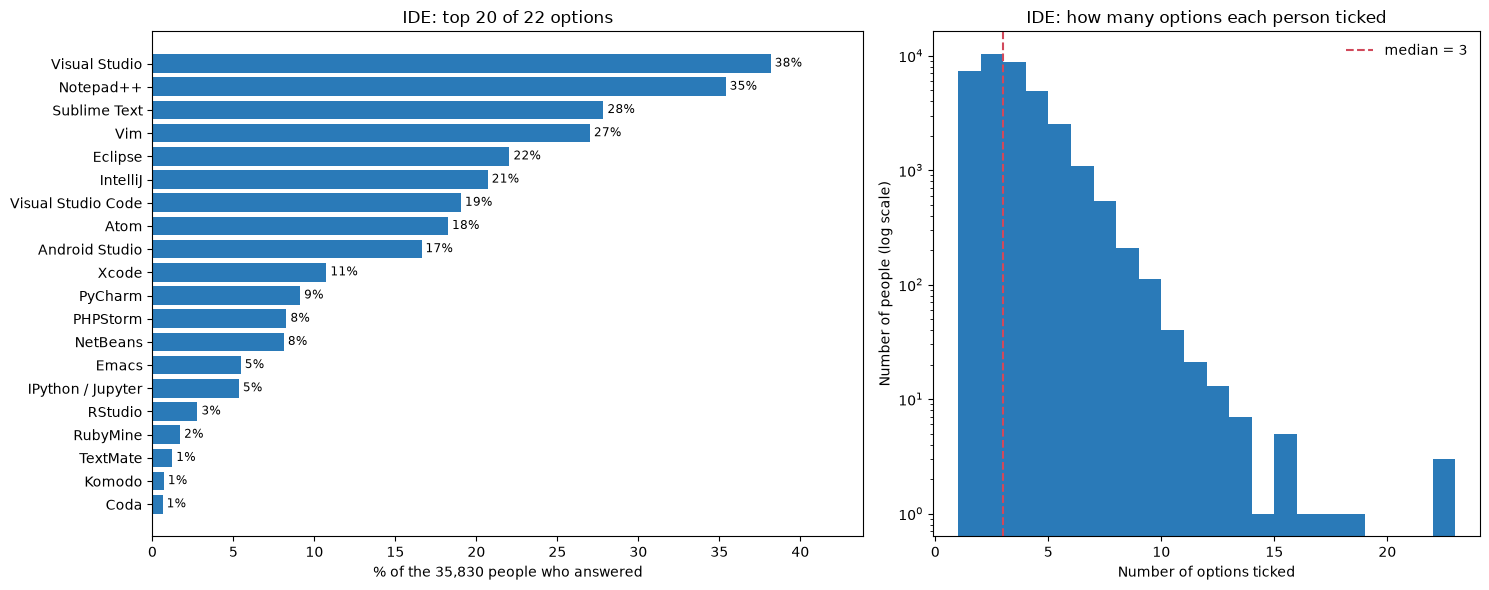

IDE: 70% answered | 22 options | median ticked 3 | ticked ALL 22: 3


,Android Studio,Atom,Coda,Eclipse,Emacs,IPython / Jupyter,IntelliJ,Komodo,Light Table,NetBeans,...,PyCharm,RStudio,RubyMine,Sublime Text,TextMate,Vim,Visual Studio,Visual Studio Code,Xcode,Zend
0,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,1,0,0,0,0,0,0,0,0,...,1,0,1,0,0,1,1,1,0,0
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,1,1,1,0,0,1,0
5,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51386,1,0,0,1,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
51387,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
51388,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
51390,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [29]:
explore_multiselect(df, "WantWorkLanguage")       # languages they want to use next
explore_multiselect(df, "HaveWorkedDatabase")
explore_multiselect(df, "HaveWorkedPlatform")
explore_multiselect(df, "DeveloperType")
explore_multiselect(df, "IDE")

### 8. Multi-select questions - analysis

What it shows

Left chart: most common languages (out of the 36,625 people who answered, 71% of respondents):

JavaScript 62%, SQL 51%, Java 40%, then C#, Python and PHP.
Below the top 10 it drops quickly. Rare options like Hack (107 people), Julia (138) and Dart (145) are too small to be useful features. This is the same small-group problem as Step 5.

Right chart: languages per person:

Most people ticked 2–5 (median 3), which is believable.
The counts drop steadily as the number goes up, then jump back up at 35: 11 people ticked every single language. Nobody has really worked in all 35, including Hack, Common Lisp and Visual Basic 6. They probably clicked everything to get through the survey, or were joking.
The log scale is why that spike is visible at all. On a normal scale, 11 people would be too small to see next to 8,000.


### 9. The numeric columns - code

2017 has only four numeric columns besides salary. This step checks whether their values make sense, then sees which ones move together.

Question: do the 0–10 ratings look reasonable?
Charts: histograms of CareerSatisfaction, JobSatisfaction and HoursPerWeek, plus a correlation matrix (Lecture 1) for those numeric columns plus salary.
Why: it checks for impossible values (none so far: all are in range) and shows which columns move together.

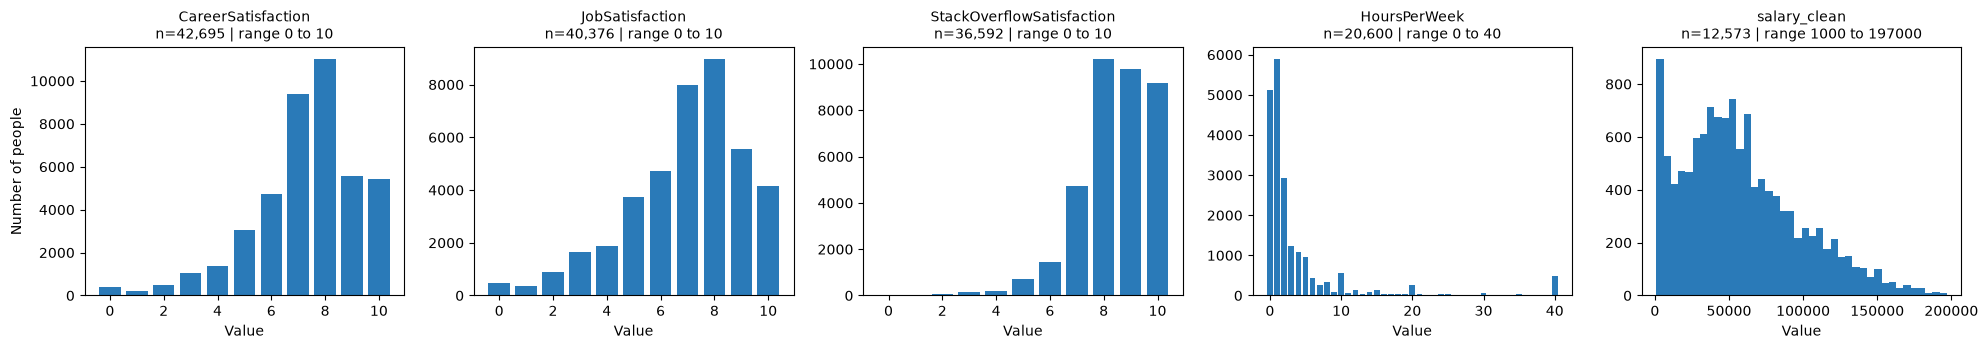

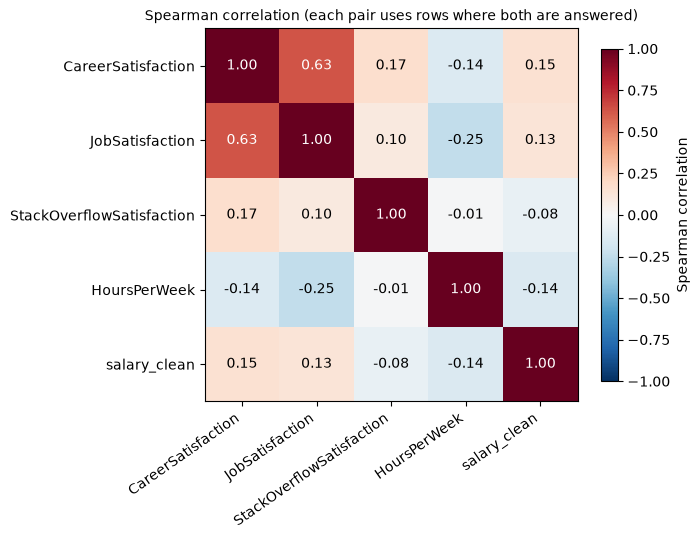

In [30]:
import numpy as np

def plot_numeric(df, cols):
    """One distribution chart per numeric column."""
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.6))
    for ax, c in zip(axes, cols):
        s = df[c].dropna()
        if s.nunique() <= 41:                      # few distinct values → one bar per value
            vals = s.value_counts().sort_index()
            ax.bar(vals.index, vals.values, color="#2a7ab8", width=0.8)
        else:                                      # many values → histogram
            ax.hist(s, bins=40, color="#2a7ab8")
        ax.set_title(f"{c}\nn={len(s):,} | range {s.min():g} to {s.max():g}", fontsize=10)
        ax.set_xlabel("Value")
    axes[0].set_ylabel("Number of people")
    plt.tight_layout(); plt.show()

def plot_correlation(df, cols, method="spearman"):
    """Correlation matrix as a colored grid."""
    corr = df[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(7, 5.8))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=35, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(v) > 0.5 else "black")
    fig.colorbar(im, ax=ax, shrink=0.8, label=f"{method.title()} correlation")
    ax.set_title(f"{method.title()} correlation (each pair uses rows where both are answered)",
                 fontsize=10)
    plt.tight_layout(); plt.show()

NUM = ["CareerSatisfaction", "JobSatisfaction", "StackOverflowSatisfaction",
       "HoursPerWeek", "salary_clean"]
plot_numeric(df, NUM)
plot_correlation(df, NUM)

### 9. The Numeric Columns -  analysis

What the distribution charts show

The three satisfaction ratings (0–10) look fine:

All values are whole numbers between 0 and 10, so there’s nothing impossible.
They’re left-skewed: most people rate 7–10. Stack Overflow satisfaction in particular is very high, which makes sense since people took a survey run by Stack Overflow. Because nearly everyone gives a similar answer, it’s not very useful as a feature.

HoursPerWeek doesn’t measure what its name suggests. The schema shows it means hours per week spent looking for a new job, not hours worked. This is why you always check schema.csv before trusting a column name. Other problems:

Only 40% answered (20,600 people).
There’s a spike at exactly 40 (476 people). The survey used a slider that stopped at 40, so “40” really means “40 or more”. A value that’s capped like this is called top-coded, like salary’s $197k ceiling.
There are spikes at round numbers (10, 20, 30). People estimate; they didn’t count exactly.
Some answers contradict each other: 338 people said they’re “Not employed, and not looking for work” but still reported hours spent job-hunting, and 47 of them said 10+ hours. That’s either a mistake or a different reading of the question. Flag it.

salary_clean: this is the same right-skewed shape from Step 2, now without the under-$1,000 errors.

What the correlation matrix shows

Correlation runs from −1 (one goes up, the other goes down) through 0 (no relationship) to +1 (they rise together). Red means positive, blue means negative.

Career and job satisfaction: 0.63. That’s strongly related, which makes sense. For modeling, they overlap (the multicollinearity issue from Step 4), so you might keep one or average them.
Salary and satisfaction: about 0.15. That’s weak. Higher pay goes with slightly higher satisfaction, but not by much.
Job-hunting hours and job satisfaction: −0.25. Unhappier people spend more time job hunting. That’s a sensible pattern, and a sign the data behaves as expected.
Everything else is near 0.

This matrix only covers the 5 numeric columns. Most of the useful information (country, experience, education, languages) is categorical, so it isn’t here. That’s why the box plots in Step 4 mattered more.